# Commuting zones: life-expectancy estimates with known sampling variance

Every life-expectancy figure in the Health Inequality Project tables is an
estimate with a published standard error, and those standard errors vary by
more than an order of magnitude across commuting zones because they are
driven by the number of deaths observed in each cell. The previous case
(`cz_inequality.ipynb`) modelled the estimates themselves; this one asks
what a distributional regression sees when its outcome carries that
measurement noise, and what changes when the model is told about it.

We use a location-scale model whose variance is the sum of a known
sampling component and an estimated excess component,
`v_i = s2_i + exp(eta_sigma_i)`, with `s2_i` the published squared standard
error supplied as fixed data ({cite:t}`chetty2016inequality`; eTable 8's footnote documents the
published-SE columns). Three
specifications are compared on the study-02 data: the naive GaussianLSS
fit, the inverse-variance weighted fit that is the standard applied
response, and the corrected family — `GaussianKnownVarLSS`, which this
package implements and R's gamboostLSS does not have.

This case teaches how published sampling variances enter a distributional model instead
of being treated as ordinary predictor weights. It compares naive, weighted and known-
variance fits before interpreting excess variance.


:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | what survives when the outcome is itself an estimate with a published standard error |
| **Observed response** | life expectancy at 40, supplied with its published standard error |
| **Estimand** | the association with each local characteristic after separating estimation noise from real dispersion |
| **Units** | years of life expectancy; standard errors in the same units |
| **Sampling unit** | one commuting zone, whose outcome is an estimate rather than a measurement |
| **Dependence** | spatial, as in the companion study; and the outcome's noise varies by an order of magnitude across zones, which is the study's subject |
| **Split / resampling unit** | the commuting zone |
| **Tuning** | fixed `mstop` |
| **Uncertainty** | carried by the known-variance family: the published standard error enters the model as data |
| **Claim type** | descriptive association |
:::


## Published standard errors

For men in the bottom income quartile, published standard errors run from
0.09 to 1.10 years; for women in the top quartile they reach 4.8 years.
Top-quartile cells have the fewest deaths per commuting zone. Variation among
their life-expectancy estimates therefore includes substantial sampling noise,
which a model of those estimates must distinguish from variation among areas.

In [1]:
import json
import pathlib

import altair as alt
import numpy as np
import polars as pl

import mboostrs as mb

raw = mb.datasets.hip_cz()
se = raw.select(["pop2000", "sd_le_raceadj_q1_M", "sd_le_raceadj_q4_F"])
summary = pl.DataFrame({
    "outcome": ["men Q1", "women Q1", "men Q4", "women Q4"],
    "median SE (years)": [raw[f"sd_le_raceadj_{q}_{g}"].median()
                          for q in ("q1", "q4") for g in ("F", "M")][::-1],
    "max SE (years)": [raw[f"sd_le_raceadj_{q}_{g}"].max()
                       for q in ("q1", "q4") for g in ("F", "M")][::-1],
})
display(summary)

outcome,median SE (years),max SE (years)
str,f64,f64
"""men Q1""",0.768378,4.5358644
"""women Q1""",0.798271,4.8057547
"""men Q4""",0.400029,1.1037658
"""women Q4""",0.487248,1.4027258


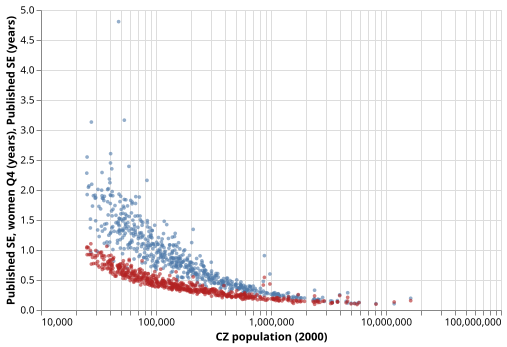

In [2]:
alt.Chart(se).transform_filter("datum.sd_le_raceadj_q4_F > 0").mark_circle(size=14, opacity=0.6).encode(
    x=alt.X("pop2000:Q", title="CZ population (2000)", scale=alt.Scale(type="log")),
    y=alt.Y("sd_le_raceadj_q4_F:Q", title="Published SE, women Q4 (years)"),
) + alt.Chart(se).mark_circle(size=14, opacity=0.6).encode(
    x=alt.X("pop2000:Q", scale=alt.Scale(type="log")),
    y=alt.Y("sd_le_raceadj_q1_M:Q", title="Published SE (years)"),
    color=alt.value("firebrick"),
).properties(width=460, height=300)

Standard error falls with population roughly as one over its square root —
the textbook sampling relationship — and the red series (men Q1) sits far
below the blue one (women Q4) at every population. The dispersion a naive
model fits is this measurement floor plus whatever real heterogeneity
exists, mixed in unknown proportions.

## The `GaussianKnownVarLSS` family

`GaussianKnownVarLSS` specifies `v_i = s2_i + exp(eta_sigma_i)`, identity
link on `mu`, and boosts only the excess log-variance. Its negative
gradients are

`u_mu = (y - mu) / v` and `u_sigma = 0.5 * exp(eta_sigma) / v * [(y - mu)^2 / v - 1]`,

where `v = s2 + exp(eta_sigma)`. The factor `exp(eta_sigma) / v` is the
correction: where the known sampling variance dominates, the sigma-gradient
is attenuated, reducing the scale update's response to sampling noise.
The finite-difference check below compares each negative gradient with the
negative derivative of the implemented risk.

In [3]:
# Finite-difference check of the family's gradients at a small configuration.
# The risk is the negative log-likelihood under v_i = s2_i + exp(eta_i).
rng = np.random.default_rng(0)
n = 8
y = rng.normal(1, 2, n)
s2 = rng.uniform(0.05, 2.0, n)
eta_mu = rng.normal(0, 1, n)
eta_sig = rng.normal(-0.5, 0.5, n)

def nll(em, es):
    v = s2 + np.exp(es)
    return float(np.sum(0.5 * np.log(2 * np.pi * v) + (y - em) ** 2 / (2 * v)))

v = s2 + np.exp(eta_sig)
u_mu = (y - eta_mu) / v                       # negative gradient, mu
u_sig = 0.5 * np.exp(eta_sig) / v * ((y - eta_mu) ** 2 / v - 1)  # sigma

# the central difference above is the GRADIENT dNLL/deta; the boosting
# ngradient is its negative — forgetting that sign is precisely the error
# class this cell exists to catch
h = 1e-6
E = np.eye(n)
d_mu = np.array([(nll(eta_mu + h * E[i], eta_sig)
                  - nll(eta_mu - h * E[i], eta_sig)) / (2 * h) for i in range(n)])
d_sig = np.array([(nll(eta_mu, eta_sig + h * E[i])
                   - nll(eta_mu, eta_sig - h * E[i])) / (2 * h) for i in range(n)])
print("max |(-dNLL/deta_mu)  - u_mu| :", np.abs(-d_mu - u_mu).max())
print("max |(-dNLL/deta_sig) - u_sig|:", np.abs(-d_sig - u_sig).max())

max |(-dNLL/deta_mu)  - u_mu| : 1.2037082997018445e-09
max |(-dNLL/deta_sig) - u_sig|: 1.1648547959541844e-09


Both differences are at the finite-difference noise floor, so the formulas
the Rust engine implements are the derivatives of the risk it reports. The
sigma gradient contains `[...] - 1`: it increases the excess variance when the
squared residual exceeds the modelled total variance.

## Naive, weighted and corrected fits

The full study offers 39 covariates to each submodel and reports selection
frequencies from 100 subsamples; those results are loaded from the
precomputed artifact below. The live demonstration uses a reduced menu —
one linear and one smooth learner on each of twelve covariates chosen to
span the groups, plus the spatial surface — with 25 subsamples, which is
enough to show the mechanism without minutes of fitting. The response is
`cbind(le, s2)`: the second column is the squared published standard
error, riding inside the response the way `Surv(time, status)` does for
survival families, so resampling keeps it aligned with the outcome.

In [4]:
MENU = ["cur_smoke_q1", "bmi_obese_q1", "exercise_any_q1",
        "puninsured2010", "reimb_penroll_adj10", "med_prev_qual_z",
        "primcarevis_10", "amb_disch_per1000_10",
        "gini99", "poor_share", "inc_share_1perc",
        "cs00_seg_inc", "cs_educ_ba", "cs_born_foreign",
        "pop_density", "subcty_exp_pc"]

complete = raw.drop_nulls(subset=["le_raceadj_q1_M",
                                  "sd_le_raceadj_q1_M",
                                  "lon", "lat", "census_div", *MENU])
frame = complete.with_columns([
    ((pl.col(c) - pl.col(c).mean()) / pl.col(c).std()).alias(c) for c in MENU
]).with_columns(
    (pl.col("sd_le_raceadj_q1_M") ** 2).alias("s2"),
)
data = {c: frame[c].to_numpy() for c in frame.columns}
data["census_division"] = frame["census_div"].cast(str).to_numpy()

mu_terms = [f"bols({c}, intercept=False)" for c in MENU] + \
           [f"bbs({c}, center=True, df=1)" for c in MENU] + \
           ["bspatial(lon, lat, df=6)"]
# sigma keeps an intercept-capable bols: a centered-only sigma basis has no
# constant direction and its level never leaves the offset
sig_terms = [f"bols({c})" for c in MENU] + \
            [f"bbs({c}, center=True, df=1)" for c in MENU] + \
            ["bspatial(lon, lat, df=6)"]

forms_corrected = {
    "mu": "cbind(le_raceadj_q1_M, s2) ~ " + " + ".join(mu_terms),
    "sigma": "cbind(le_raceadj_q1_M, s2) ~ " + " + ".join(sig_terms),
}
forms_naive = {k: v.replace("cbind(le_raceadj_q1_M, s2)", "le_raceadj_q1_M")
               for k, v in forms_corrected.items()}
print(f"{frame.height} CZs, {len(mu_terms)} mu learners, {len(sig_terms)} sigma learners")

590 CZs, 33 mu learners, 33 sigma learners


In [5]:
def fit_and_stab(forms, families):
    model = mb.gamboostLSS(forms, data=data, families=families,
                           method="noncyclic",
                           control=mb.boost_control(100, 0.1))
    stab = model.stabsel(q=8, PFER=1.0, B=25)
    rows = pl.DataFrame({
        "learner": stab.learner_names,
        "freq": np.asarray(stab.max_),
    }).with_columns(
        pl.col("learner").str.split(".").list.last().alias("param"),
        pl.col("learner").str.split(".").list.first().alias("column"),
    )
    return model, rows.filter(pl.col("freq") >= 0.5).sort("freq", descending=True)

naive_model, naive_rows = fit_and_stab(forms_naive, mb.GaussianLSS())
corrected_model, corrected_rows = fit_and_stab(forms_corrected, mb.GaussianKnownVarLSS())
print("naive sigma (freq >= 0.5):")
display(naive_rows.filter(pl.col("param") == "sigma"))
print("corrected sigma (freq >= 0.5):")
display(corrected_rows.filter(pl.col("param") == "sigma"))

naive sigma (freq >= 0.5):


/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamlss.py:4491: UserWarning: mstop too small in some subsampling replicates to select q=8 base-learners; Increase mstop before applying stabsel. 4 of 50 fits fell short (B=25 complementary pairs, 50 fits) and the best reached 8 distinct learners. A model whose path keeps re-selecting the same few terms may not reach q=8 at any mstop, in which case lower q instead: a fold that never reaches q also never stops early, so the run costs the full mstop.
  return entry(**arguments)


learner,freq,param,column
str,f64,str,str
"""lon,lat.sigma""",1.0,"""sigma""","""lon,lat"""
"""med_prev_qual_z.sigma""",0.58,"""sigma""","""med_prev_qual_z"""
"""pop_density.sigma""",0.54,"""sigma""","""pop_density"""


corrected sigma (freq >= 0.5):


learner,freq,param,column
str,f64,str,str
"""lon,lat.sigma""",0.9,"""sigma""","""lon,lat"""
"""pop_density.sigma""",0.52,"""sigma""","""pop_density"""


## Results with all 39 covariates

With all 39 covariates and 100 subsamples the pattern sharpens into the
study's two findings. First, the naive and inverse-variance weighted fits
are indistinguishable in selection — identical stable sets in all four
gender-quartile outcomes. Weighting rescales each observation's influence
on the mean model; it does not tell the sigma-submodel that the weights
already encode the noise, so sigma absorbs the same structure either way.
Second, the correction changes what sigma keeps: the naive sigma-submodels
of both Q4 outcomes select inequality and segregation covariates —
segregation of poverty at 0.92 for women Q4 — and the corrected models drop
them, because those covariates were tracking where the estimates are noisy
rather than where life expectancy varies.

In [6]:
results = json.loads(pathlib.Path("cz_known_variance.json").read_text())
rows = []
for key, m in results["models"].items():
    outcome, spec = key.rsplit("_", 1)
    label = {"le_raceadj_q1_M": "men Q1", "le_raceadj_q1_F": "women Q1",
             "le_raceadj_q4_M": "men Q4", "le_raceadj_q4_F": "women Q4"}[outcome]
    for r in m["sigma"][:4]:
        rows.append({"outcome": label, "spec": spec,
                     "sigma covariate": r["column"], "freq": r["freq"]})
sig_table = pl.DataFrame(rows).filter(pl.col("freq") >= 0.6)
display(sig_table.pivot("spec", index=["outcome", "sigma covariate"],
                        values="freq").sort("outcome"))

outcome,sigma covariate,naive,weighted,corrected
str,str,f64,f64,f64
"""men Q1""","""lon,lat""",1.0,1.0,1.0
"""men Q1""","""med_prev_qual_z""",0.84,0.84,null
"""men Q4""","""lon,lat""",0.8,0.8,null
"""men Q4""","""cs00_seg_inc""",0.72,0.72,null
"""men Q4""","""cur_smoke_q1""",0.64,0.64,null
…,…,…,…,…
"""women Q1""","""lon,lat""",1.0,1.0,1.0
"""women Q1""","""rel_tot""",0.76,0.76,null
"""women Q4""","""lon,lat""",1.0,1.0,null


## Sampling and excess variance

The corrected fit splits the average predictive variance into its known
sampling part and its estimated excess. The share that is estimation noise
rises steeply across the income distribution: about a quarter for Q1 men,
three quarters for Q4 women. Cross-CZ dispersion in top-quartile women's
life expectancy is mostly a statement about small death counts.

One condition bounds these numbers: the split depends on how much mean
structure the mu-submodel has extracted when it is read. Boosting shrinks,
so at an early stop much real heterogeneity still sits in sigma, while a
deep fit attributes more of the cross-CZ variance to covariates and leaves
less excess. The chart shows the measured path.

mstop,mean excess variance,mean sampling variance
i64,f64,f64
100,0.873607,0.254628
500,0.454613,0.254628
2000,0.236456,0.254628


/tmp/ipykernel_67194/1259547971.py:9: DeprecationWarning: `DataFrame.melt` is deprecated; use `DataFrame.unpivot` instead, with `index` instead of `id_vars` and `on` instead of `value_vars`
  alt.Chart(path.melt(id_vars="mstop", value_name="variance",


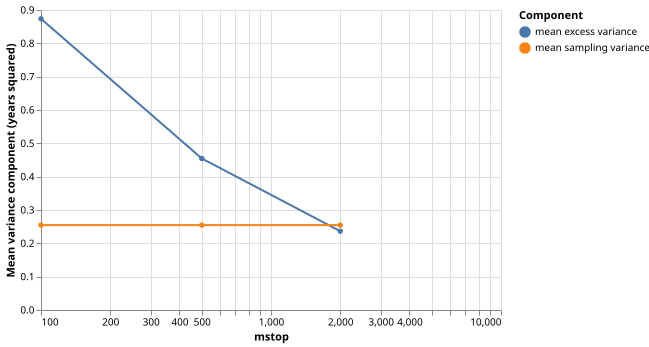

In [7]:
sens = results["sensitivity"]["le_raceadj_q1_M"]
path = pl.DataFrame({
    "mstop": [p["mstop"] for p in sens["path"]],
    "mean excess variance": [p["mean_excess_variance"] for p in sens["path"]],
}).with_columns(
    (pl.lit(sens["mean_sampling_variance"])).alias("mean sampling variance"),
)
display(path)
alt.Chart(path.melt(id_vars="mstop", value_name="variance",
                    variable_name="component")).mark_line(point=True).encode(
    x=alt.X("mstop:Q", title="mstop", scale=alt.Scale(type="log")),
    y=alt.Y("variance:Q", title="Mean variance component (years squared)"),
    color=alt.Color("component:N", title="Component"),
).properties(width=460, height=300)

In [8]:
comp = []
for key, m in results["models"].items():
    if "decomposition" not in m or key.rsplit("_", 1)[1] != "corrected":
        continue
    outcome = key.rsplit("_", 1)[0]
    label = {"le_raceadj_q1_M": "men Q1", "le_raceadj_q1_F": "women Q1",
             "le_raceadj_q4_M": "men Q4", "le_raceadj_q4_F": "women Q4"}[outcome]
    d = m["decomposition"]
    comp.append({"outcome": label,
                 "sampling": d["mean_sampling_variance"],
                 "excess": d["mean_excess_variance"],
                 "sampling share of predictive": d["sampling_share_of_predictive"]})
display(pl.DataFrame(comp).sort("outcome"))

outcome,sampling,excess,sampling share of predictive
str,f64,f64,f64
"""men Q1""",0.254628,0.873607,0.225687
"""men Q4""",1.178432,0.744241,0.612913
"""women Q1""",0.389222,0.661321,0.370496
"""women Q4""",1.257188,0.471377,0.727302


## Limitations

The units are areas and the estimates are ecological, as in the previous
case. The variance decomposition assumes the sampling error is additive and
independent of the excess variation; if places with unusual mortality also
have unusual estimation error, the split is biased at the margin, and the
published standard errors are themselves model-based. The decomposition is
read at the cvrisk-chosen stopping iteration, which prefers heavy shrinkage
— so any quoted variance share should be read alongside the stopping-path
sensitivity table above. And the corrected sigma estimates, like all boosted partial
effects, are shrunken shapes rather than unbiased variance components.